# EDA — application-time gold features

Explore the current gold store before choosing additional features. No model is trained here. Features are joined to `30dpd_6mob` labels at loan start, six months before label observation. Candidate ratios are computed in memory; stored partitions are not changed.

The latest three label months are reserved and excluded from target-based feature exploration. Existing full-data EDA was previously performed, so this is not a pristine untouched holdout; a future cohort is preferable for final confirmation. Application-month feature availability is a source assumption, not something that date checks alone can prove.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from IPython.display import display

if Path.cwd().name == 'notebooks':
    os.chdir('..')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)
GOLD = Path('datamart/gold')
LABEL_MOB = 6


## 1. Grain, dates and label join

In [2]:
features = pd.read_parquet(GOLD / 'features_store')
labels = pd.read_parquet(GOLD / 'label_store')
features['snapshot_date'] = pd.to_datetime(features['snapshot_date'])
assert set(labels['label_def'].unique()) == {'30dpd_6mob'}
assert not features.duplicated(['customer_id', 'snapshot_date']).any()
assert labels['loan_id'].is_unique
labels = labels.rename(columns={'snapshot_date': 'label_date'})
labels['label_date'] = pd.to_datetime(labels['label_date'])
labels['loan_start_date'] = labels['label_date'] - pd.DateOffset(months=LABEL_MOB)
joined = labels.merge(features, left_on=['customer_id', 'loan_start_date'],
                      right_on=['customer_id', 'snapshot_date'], how='left',
                      validate='many_to_one', indicator=True)
assert joined['_merge'].eq('both').all(), 'Some labels lack application features'
assert joined['snapshot_date'].eq(joined['loan_start_date']).all()
assert joined['snapshot_date'].lt(joined['label_date']).all()
reserved_start = labels['label_date'].max() - pd.DateOffset(months=2)
df = joined.loc[joined['label_date'] < reserved_start].drop(columns='_merge').copy()
print(f'Gold features: {features.shape}; labels: {labels.shape}; matched: {len(joined)}')
print(f'Development rows: {len(df)}; reserved rows: {len(joined)-len(df)}')
print('Reserved label dates start:', reserved_start.date())
print('Development label dates:', df['label_date'].min().date(), 'to', df['label_date'].max().date())
CS = [c for c in features if c.startswith('fe_')]
CATEGORICAL = features.select_dtypes(include=['object', 'string']).columns.difference(['customer_id']).tolist()
NUMERIC = features.select_dtypes('number').columns.tolist()


Gold features: (12500, 45); labels: (12500, 6); matched: 12500
Development rows: 10971; reserved rows: 1529
Reserved label dates start: 2025-05-01
Development label dates: 2023-07-01 to 2025-04-01


## 2. Development target and coverage over time

Development default rate: 29.022% (3184/10971)


,n,defaults,default_rate
label_date,,,
2023-07,530,140,0.264
2023-08,501,154,0.307
2023-09,506,162,0.320
2023-10,510,137,0.269
2023-11,521,139,0.267
2023-12,517,137,0.265
2024-01,471,140,0.297
2024-02,481,139,0.289
2024-03,454,119,0.262


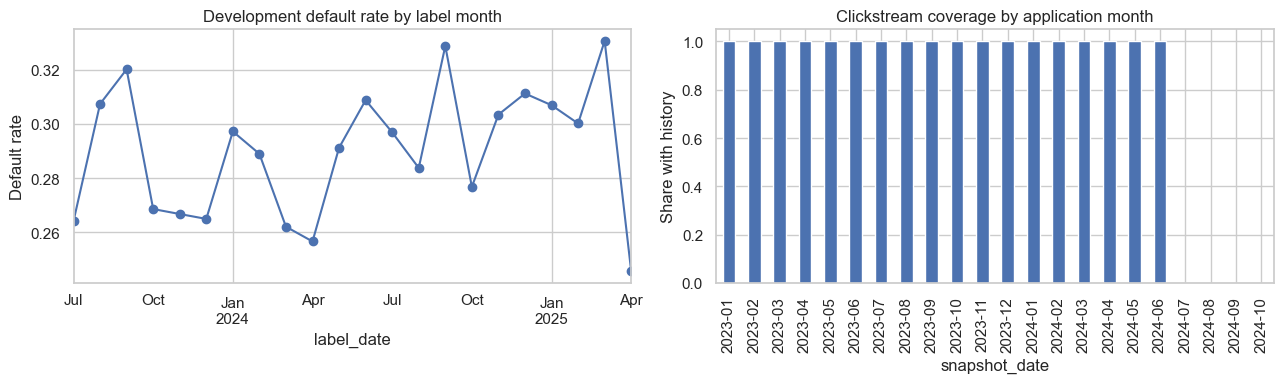

In [3]:
monthly = df.groupby(df['label_date'].dt.to_period('M'))['label'].agg(n='size', defaults='sum', default_rate='mean')
print(f"Development default rate: {df['label'].mean():.3%} ({df['label'].sum()}/{len(df)})")
display(monthly.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly['default_rate'].plot(marker='o', ax=axes[0], title='Development default rate by label month')
axes[0].set_ylabel('Default rate')
coverage = df.groupby(df['snapshot_date'].dt.to_period('M'))['has_clickstream'].agg(n='size', coverage='mean')
coverage['coverage'].plot.bar(ax=axes[1], title='Clickstream coverage by application month')
axes[1].set_ylabel('Share with history')
plt.tight_layout(); plt.show()


## 3. Missingness, outliers and source consistency
Missingness associations are descriptive and include sample counts. Quantiles below are summaries, not preprocessing thresholds.

In [4]:
missing = pd.DataFrame({'missing_pct': df[NUMERIC + CATEGORICAL].isna().mean() * 100})
for c in missing.index:
    mask = df[c].isna()
    missing.loc[c, 'n_missing'] = mask.sum()
    missing.loc[c, 'default_missing'] = df.loc[mask, 'label'].mean()
    missing.loc[c, 'default_present'] = df.loc[~mask, 'label'].mean()
display(missing.query('missing_pct > 0').sort_values('missing_pct', ascending=False).round(3))
financial = [c for c in NUMERIC if c not in CS and c != 'has_clickstream']
display(df[financial].describe(percentiles=[.01, .5, .95, .99]).T.round(3))
salary_ratio = df['annual_income'] / (12 * df['monthly_inhand_salary'].where(df['monthly_inhand_salary'] > 0))
print('Annual income / (12 × monthly salary) quantiles:')
display(salary_ratio.quantile([0, .01, .5, .95, .99, 1]).round(3))
print('Rows with annual income > 10 × annualized take-home salary:', int((salary_ratio > 10).sum()))
print('This flags inconsistencies for review; gross and take-home income need not be equal.')


,missing_pct,n_missing,default_missing,default_present
credit_mix,20.855,2288.0,0.281,0.293
fe_5_mean_12m,18.203,1997.0,0.297,0.289
fe_10_mean_12m,18.203,1997.0,0.297,0.289
fe_8_mean_12m,18.203,1997.0,0.297,0.289
fe_7_mean_12m,18.203,1997.0,0.297,0.289
fe_6_mean_12m,18.203,1997.0,0.297,0.289
fe_11_mean_12m,18.203,1997.0,0.297,0.289
fe_4_mean_12m,18.203,1997.0,0.297,0.289
fe_3_mean_12m,18.203,1997.0,0.297,0.289
fe_2_mean_12m,18.203,1997.0,0.297,0.289


,count,mean,std,min,1%,50%,95%,99%,max
age,10119.0,34.657,10.154,18.000,18.000,34.000,53.000,55.000,5.600000e+01
annual_income,10971.0,164448.391,1318732.750,7005.930,7530.158,37471.520,134318.820,178860.755,2.383470e+07
monthly_inhand_salary,10971.0,4185.885,3188.141,319.560,528.041,3081.240,10795.780,13782.069,1.520463e+04
num_bank_accounts,10822.0,5.362,2.603,0.000,0.000,5.000,10.000,10.000,1.100000e+01
num_credit_card,10706.0,5.554,2.074,0.000,1.000,5.000,10.000,10.000,1.100000e+01
interest_rate,10732.0,14.570,8.783,1.000,1.000,13.000,31.000,34.000,3.400000e+01
num_of_loan,10922.0,3.554,2.484,0.000,0.000,3.000,8.000,9.000,3.300000e+01
delay_from_due_date,10891.0,21.262,14.869,0.000,0.000,18.000,54.000,61.000,6.700000e+01
num_of_delayed_payment,10801.0,13.403,6.216,0.000,0.000,14.000,23.000,25.000,2.800000e+01
changed_credit_limit,10744.0,10.391,6.800,-6.490,-1.926,9.400,23.600,28.790,3.697000e+01


Annual income / (12 × monthly salary) quantiles:


0.00       0.674
0.01       0.770
0.50       1.004
0.95       1.218
0.99       1.696
1.00    3859.615
dtype: float64

Rows with annual income > 10 × annualized take-home salary: 99
This flags inconsistencies for review; gross and take-home income need not be equal.


## 4. Existing feature signal
Univariate AUC measures ranking by one feature on nonmissing development rows. Below 0.5 indicates an inverse association. Ranking AUC flips the direction for comparison; it does not measure added value in a model.

In [5]:
def profile_auc(data, columns):
    rows = []
    for c in columns:
        s = data[[c, 'label']].replace([np.inf, -np.inf], np.nan).dropna()
        auc = roc_auc_score(s['label'], s[c]) if s['label'].nunique() == 2 else np.nan
        rows.append({'feature': c, 'n': len(s), 'missing_pct': 100 * (1-len(s)/len(data)),
                     'auc': auc, 'ranking_auc': max(auc, 1-auc),
                     'median_nondefault': s.loc[s['label']==0, c].median(),
                     'median_default': s.loc[s['label']==1, c].median()})
    return pd.DataFrame(rows).set_index('feature').sort_values('ranking_auc', ascending=False)
existing_auc = profile_auc(df, NUMERIC)
display(existing_auc.round(3))
for c in CATEGORICAL:
    print(c)
    display(df.groupby(df[c].fillna('MISSING'))['label'].agg(n='size', default_rate='mean').round(3))


,n,missing_pct,auc,ranking_auc,median_nondefault,median_default
feature,,,,,,
outstanding_debt,10971,0.000,0.725,0.725,948.380,1821.320
interest_rate,10732,2.178,0.720,0.720,11.000,20.000
num_credit_inquiries,10804,1.522,0.706,0.706,5.000,9.000
delay_from_due_date,10891,0.729,0.696,0.696,15.000,26.000
credit_history_months,10971,0.000,0.311,0.689,242.000,167.500
num_credit_card,10706,2.415,0.678,0.678,5.000,6.000
num_of_loan,10922,0.447,0.671,0.671,3.000,5.000
fe_5_mean_12m,8974,18.203,0.670,0.670,100.750,124.500
fe_10_mean_12m,8974,18.203,0.334,0.666,125.000,101.250


credit_mix


,n,default_rate
credit_mix,,
Bad,2098,0.561
Good,2676,0.163
MISSING,2288,0.281
Standard,3909,0.238


occupation


,n,default_rate
occupation,,
Accountant,703,0.306
Architect,700,0.276
Developer,684,0.292
Doctor,674,0.289
Engineer,690,0.306
Entrepreneur,682,0.284
Journalist,682,0.287
Lawyer,726,0.269
MISSING,774,0.293


payment_of_min_amount


,n,default_rate
payment_of_min_amount,,
NM,1279,0.294
No,3935,0.142
Yes,5757,0.390


## 5. Proposed affordability features — exploratory only
Use the same formulas and validity guards as the proposed gold implementation. Original measurements remain available. Negative income after EMI is retained. This amount excludes living expenses, so it is not disposable income.

In [6]:
RATIOS = {
    'emi_to_monthly_income': ('total_emi_per_month', 'monthly_inhand_salary'),
    'debt_to_annual_income': ('outstanding_debt', 'annual_income'),
    'debt_to_monthly_income': ('outstanding_debt', 'monthly_inhand_salary'),
    'balance_to_monthly_income': ('monthly_balance', 'monthly_inhand_salary'),
    'investment_to_monthly_income': ('amount_invested_monthly', 'monthly_inhand_salary'),
}
for name, (num, den) in RATIOS.items():
    valid = (df[den] > 0) & (df[num] >= 0)
    df[name] = (df[num] / df[den].where(df[den] > 0)).where(valid)
valid = (df['monthly_inhand_salary'] > 0) & (df['total_emi_per_month'] >= 0)
df['monthly_income_after_emi'] = (df['monthly_inhand_salary'] - df['total_emi_per_month']).where(valid)
CANDIDATES = list(RATIOS) + ['monthly_income_after_emi']
assert not np.isinf(df[CANDIDATES].to_numpy()).any()
candidate_auc = profile_auc(df, CANDIDATES)
display(candidate_auc.round(4))
display(df[CANDIDATES].describe(percentiles=[.01, .5, .95, .99]).T.round(4))


,n,missing_pct,auc,ranking_auc,median_nondefault,median_default
feature,,,,,,
debt_to_monthly_income,10971,0.0000,0.7009,0.7009,0.239500,0.694200
debt_to_annual_income,10971,0.0000,0.6998,0.6998,0.019400,0.056900
emi_to_monthly_income,10558,3.7645,0.6310,0.6310,0.022000,0.034100
monthly_income_after_emi,10558,3.7645,0.4041,0.5959,3162.848633,2579.916504
balance_to_monthly_income,10970,0.0091,0.5434,0.5434,0.114200,0.124300
investment_to_monthly_income,10475,4.5210,0.5400,0.5400,0.042000,0.049200


,count,mean,std,min,1%,50%,95%,99%,max
emi_to_monthly_income,10558.0,0.0314,0.0287,0.0000,0.0000,0.0250,0.0830,0.1438,0.5041
debt_to_annual_income,10971.0,0.0605,0.0878,0.0000,0.0002,0.0280,0.2446,0.4519,0.6833
debt_to_monthly_income,10971.0,0.7539,1.1526,0.0000,0.0053,0.3434,3.0067,5.5843,12.7623
balance_to_monthly_income,10970.0,0.1431,0.0985,0.0001,0.0119,0.1163,0.3377,0.5139,0.8424
investment_to_monthly_income,10475.0,0.0526,0.0329,0.0000,0.0075,0.0444,0.1181,0.1330,0.1542
monthly_income_after_emi,10558.0,4038.1338,3111.1150,294.4007,493.2966,2981.4570,10515.6914,13568.3594,15101.9404


### Compare against raw inputs on identical rows
Complete-case comparisons avoid differences caused solely by unequal missingness. They still cannot establish incremental model benefit.

In [7]:
comparisons = []
for candidate in CANDIDATES:
    inputs = RATIOS.get(candidate, ('monthly_inhand_salary', 'total_emi_per_month'))
    same = df[[candidate, *inputs, 'label']].dropna()
    summary = profile_auc(same, [candidate, *inputs])
    comparisons.append({'candidate': candidate, 'n_same_rows': len(same),
                        'candidate_ranking_auc': summary.loc[candidate, 'ranking_auc'],
                        'best_input_ranking_auc': summary.loc[list(inputs), 'ranking_auc'].max(),
                        'rho_with_first_input': same[candidate].corr(same[inputs[0]], method='spearman'),
                        'rho_with_second_input': same[candidate].corr(same[inputs[1]], method='spearman')})
comparison = pd.DataFrame(comparisons).set_index('candidate')
comparison['ranking_auc_difference'] = comparison['candidate_ranking_auc'] - comparison['best_input_ranking_auc']
display(comparison.round(4))


,n_same_rows,candidate_ranking_auc,best_input_ranking_auc,rho_with_first_input,rho_with_second_input,ranking_auc_difference
candidate,,,,,,
emi_to_monthly_income,10558,0.6310,0.5941,0.6662,-0.2483,0.0369
debt_to_annual_income,10971,0.6998,0.7246,0.8214,-0.7378,-0.0247
debt_to_monthly_income,10971,0.7009,0.7246,0.8332,-0.7312,-0.0237
balance_to_monthly_income,10970,0.5434,0.6062,-0.1414,-0.8480,-0.0628
investment_to_monthly_income,10475,0.5400,0.5968,0.4946,-0.3083,-0.0567
monthly_income_after_emi,10558,0.5959,0.5941,0.9993,0.4491,0.0018


### Risk curves and redundancy
Development deciles are for plotting only. Do not reuse full-data quantiles as training transformations. Labels are associated with these features; this does not establish causality.

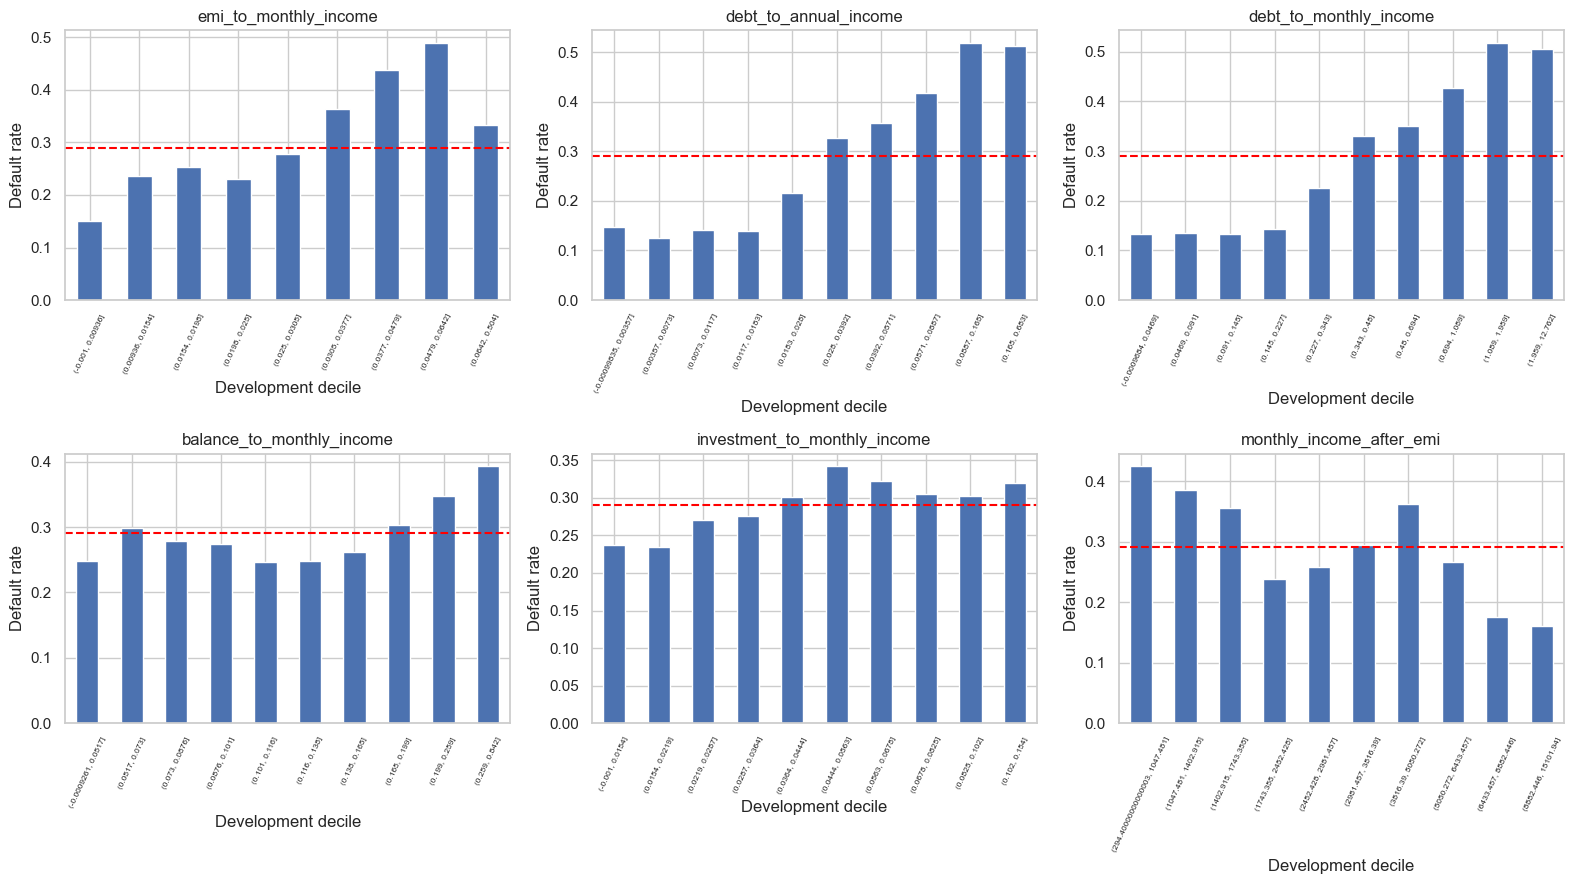

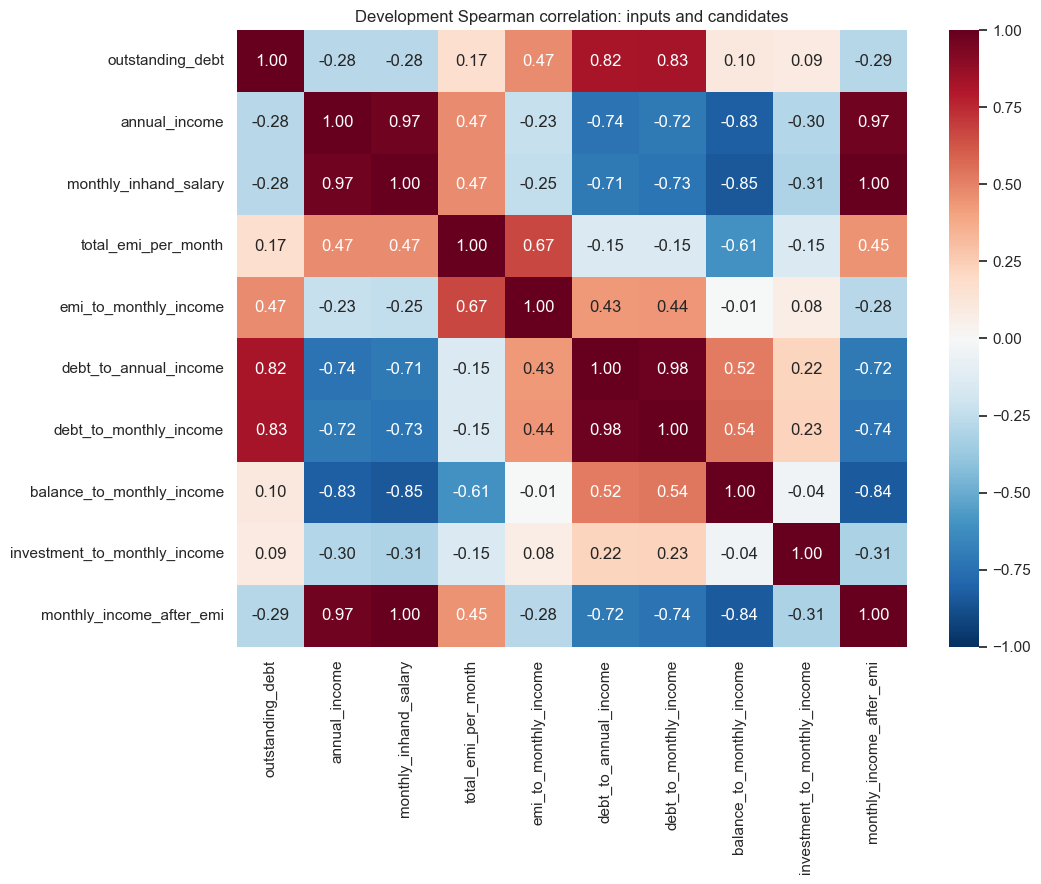

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.flat, CANDIDATES):
    bins = pd.qcut(df[c], 10, duplicates='drop')
    rates = df.groupby(bins, observed=True)['label'].agg(n='size', rate='mean')
    rates['rate'].plot.bar(ax=ax)
    ax.axhline(df['label'].mean(), color='red', linestyle='--')
    ax.set_title(c); ax.set_xlabel('Development decile'); ax.set_ylabel('Default rate')
    ax.tick_params(axis='x', labelsize=6, rotation=65)
plt.tight_layout(); plt.show()
selected = ['outstanding_debt', 'annual_income', 'monthly_inhand_salary', 'total_emi_per_month'] + CANDIDATES
corr = df[selected].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Development Spearman correlation: inputs and candidates')
plt.tight_layout(); plt.show()


### Candidate associations by development period
Use fixed chronological blocks to check whether an association changes direction. Small block differences do not prove drift or stability.

In [9]:
df['eda_period'] = np.where(df['label_date'] < '2024-07-01', 'early', 'late development')
period_auc = pd.concat({period: profile_auc(part, CANDIDATES)[['n', 'auc', 'ranking_auc']]
                        for period, part in df.groupby('eda_period')}, names=['period', 'feature'])
display(period_auc.round(4))
print('Correlation between the two debt ratios:', round(df['debt_to_annual_income'].corr(df['debt_to_monthly_income'], method='spearman'), 4))


n     auc  ranking_auc
period           feature                                                
early            debt_to_annual_income         5958  0.7000       0.7000
                 debt_to_monthly_income        5958  0.7000       0.7000
                 emi_to_monthly_income         5735  0.6350       0.6350
                 monthly_income_after_emi      5735  0.4095       0.5905
                 investment_to_monthly_income  5698  0.5444       0.5444
                 balance_to_monthly_income     5958  0.5316       0.5316
late development debt_to_monthly_income        5013  0.7014       0.7014
                 debt_to_annual_income         5013  0.6992       0.6992
                 emi_to_monthly_income         4823  0.6259       0.6259
                 monthly_income_after_emi      4823  0.3984       0.6016
                 balance_to_monthly_income     5012  0.5564       0.5564
                 investment_to_monthly_income  4777  0.5347       0.5347

Correlation between the two debt ratios: 0.98


## 6. Interpretation and next decision

Read the executed comparisons below before retaining candidates. Strong raw-feature or ratio AUC alone does not show that a ratio improves a classifier already using its inputs.

- Prefer a compact set when two candidates carry nearly identical rankings.
- Inspect annual-income inconsistencies before relying on an annual-income denominator. Do not cap automatically from a full-data percentile.
- Low EMI-to-income association may reflect how the existing EMI field is generated or measured; it is not evidence that repayment affordability is unimportant in real lending.
- Clickstream coverage depends on the cohort. Missing current-month clickstream cannot be explained just by its end date: some application cohorts have no customer history at all. Compare coverage and applicant composition explicitly.
- Future clickstream remains unavailable at application time even if its measured performance resembles past clickstream. That comparison cannot establish absence of leakage.
- Leave candidates provisional until a fixed development validation comparison measures incremental value. Keep preprocessing fitted on training only and reserve a future cohort for confirmation.


## 7. Findings from this run

Development sample: **10,971 applications**. Labels from **2025-05 through 2025-07** were excluded from the feature comparisons.

| Candidate | Ranking AUC | Strongest raw input AUC on identical rows | EDA decision |
| --- | --- | --- | --- |
| EMI / monthly income | 0.631 | 0.594 | Prioritise for a later validation comparison |
| Debt / annual income | 0.700 | 0.725 | Do not keep both debt ratios by default; annual income has inconsistencies |
| Debt / monthly income | 0.701 | 0.725 | Optional interaction candidate; does not beat raw debt univariately |
| Balance / monthly income | 0.543 | 0.606 | Low priority |
| Investment / monthly income | 0.540 | 0.597 | Low priority |
| Income after EMI | 0.596 | 0.594 | Nearly redundant with salary (Spearman 0.9993) |

EMI-to-income ranking AUC is 0.635 in the early period and 0.626 in late development, with the same direction. This is descriptive support for evaluating it, not proof of improvement after adding it to a model.

**Data quality:** 99 development rows have annual income exceeding ten times annualized take-home salary. Review source values before relying on annual-income ratios; do not silently replace them with salary × 12.

**Recommendation:** evaluate EMI-to-monthly-income first. If testing a debt ratio, prefer the monthly-income version initially and compare it against a baseline containing raw debt and salary. Balance/investment ratios and income-after-EMI do not currently justify automatic inclusion. After this EDA, the gold pipeline was reduced to EMI-to-monthly-income only and the stored gold features were updated. The other five remain exploratory candidates in this notebook. No model has been trained to measure incremental benefit.
